# Andhra Pradesh: Rainfall and Crop Production (EDA)

I'm from Guntur, so I wanted to look at two things that matter a lot here: how much it rains and what the districts grow.

**Data**
- IMD sub-division monthly rainfall, 1901-2017 (data.gov.in). AP is split into two sub-divisions: *Coastal Andhra Pradesh* and *Rayalaseema*.
- District-wise, season-wise crop production for AP, 1997-2014 (data.gov.in). Area is in hectares and production in tonnes.

**Questions**
1. How much rain does each region get, and when?
2. Is rainfall going up or down over 117 years? How often are there drought years?
3. Which crops and districts matter most?
4. Does rainfall actually affect crop yield?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
IMG = "../images/"

## 1. Rainfall data

In [2]:
rain = pd.read_csv("../data/raw/Sub_Division_IMD_2017.csv")
print(rain.shape)
rain.head()

(4188, 19)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [3]:
ap_rain = rain[rain["SUBDIVISION"].isin(["Coastal Andhra Pradesh", "Rayalseema"])].copy()
ap_rain["SUBDIVISION"] = ap_rain["SUBDIVISION"].replace({"Rayalseema": "Rayalaseema"})  # spelling in the file is different
print(ap_rain.shape)
print("missing values:", ap_rain.isna().sum().sum())
ap_rain.groupby("SUBDIVISION")["ANNUAL"].describe().round(1)

(234, 19)
missing values: 0


,count,mean,std,min,25%,50%,75%,max
SUBDIVISION,,,,,,,,
Coastal Andhra Pradesh,117.0,1050.3,189.8,703.2,892.7,1024.6,1155.1,1712.4
Rayalaseema,117.0,765.0,150.6,433.4,651.5,743.6,869.3,1277.7


No missing values for the two AP sub-divisions, so no cleaning needed here. Coastal AP gets about 1050 mm a year on average and Rayalaseema only about 765 mm.

### When does it rain?

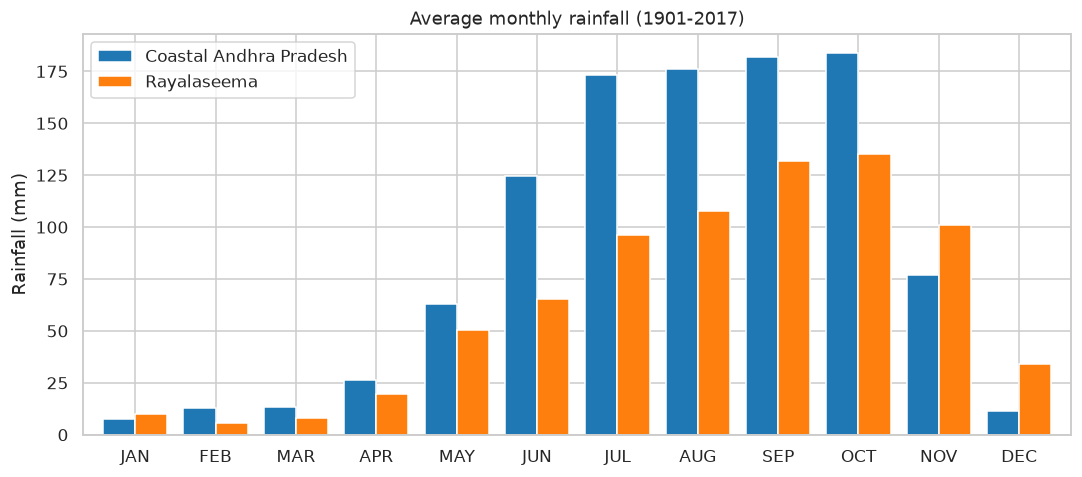

SUBDIVISION,Coastal Andhra Pradesh,Rayalaseema
JAN,7.0,10.0
FEB,13.0,6.0
MAR,13.0,8.0
APR,26.0,20.0
MAY,63.0,51.0
JUN,124.0,65.0
JUL,173.0,96.0
AUG,176.0,107.0
SEP,182.0,132.0
OCT,184.0,135.0


In [4]:
months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
monthly_avg = ap_rain.groupby("SUBDIVISION")[months].mean().T

ax = monthly_avg.plot(kind="bar", figsize=(10, 4.5), color=["#1f77b4", "#ff7f0e"], width=0.8)
ax.set_title("Average monthly rainfall (1901-2017)")
ax.set_ylabel("Rainfall (mm)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.savefig(IMG + "monthly_rainfall.png")
plt.show()

monthly_avg.round(0)

In [5]:
# share of the year's rain from the south-west monsoon (Jun-Sep) and north-east monsoon (Oct-Dec)
season_share = ap_rain.groupby("SUBDIVISION")[["JJAS", "OND", "ANNUAL"]].mean()
season_share["SW monsoon %"] = (season_share["JJAS"] / season_share["ANNUAL"] * 100).round(1)
season_share["NE monsoon %"] = (season_share["OND"] / season_share["ANNUAL"] * 100).round(1)
season_share[["SW monsoon %", "NE monsoon %"]]

,SW monsoon %,NE monsoon %
SUBDIVISION,,
Coastal Andhra Pradesh,62.4,25.9
Rayalaseema,52.4,35.4


**Observations**
- In Coastal AP the wettest month is actually **October** (184 mm), not July or August. That is the north-east monsoon and the cyclones from the Bay of Bengal.
- Rayalaseema depends on the north-east monsoon even more: about 35% of its rain comes in Oct-Dec, compared to 26% for Coastal AP.
- So for AP, a "normal monsoon" in June-September is only part of the story.

### Long-term trend

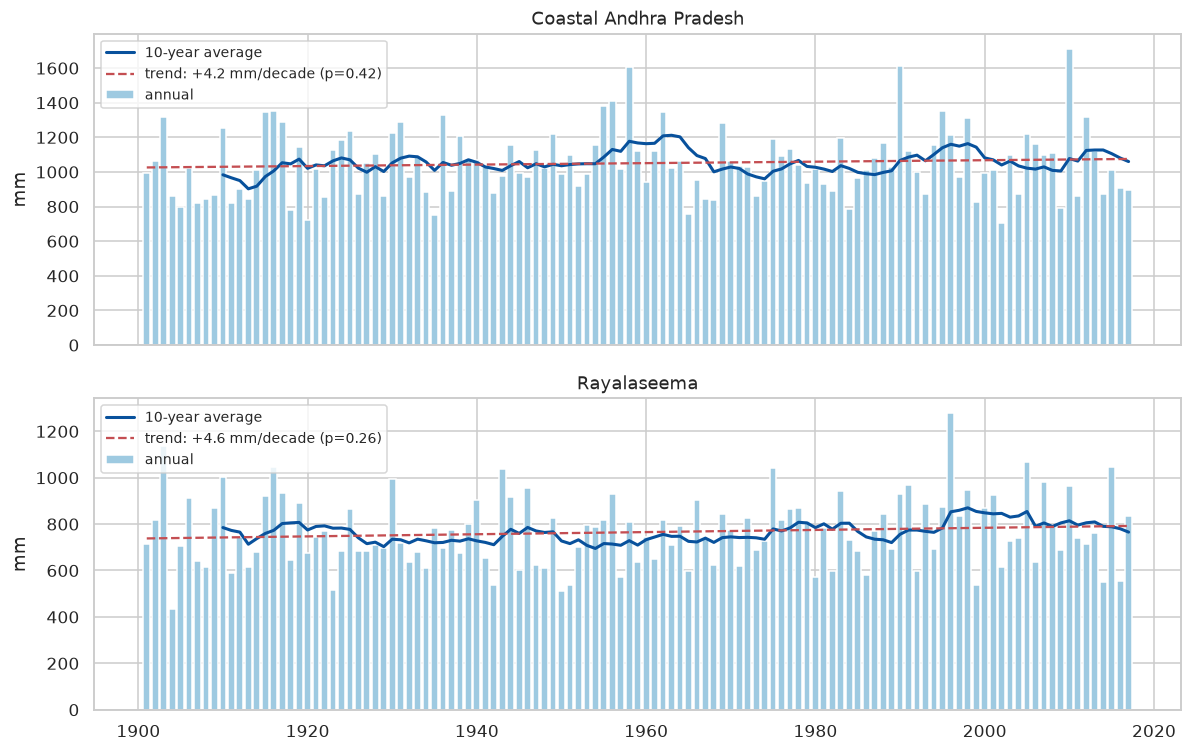

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for ax, (name, g) in zip(axes, ap_rain.groupby("SUBDIVISION")):
    g = g.sort_values("YEAR")
    ax.bar(g["YEAR"], g["ANNUAL"], color="#9ecae1", label="annual")
    ax.plot(g["YEAR"], g["ANNUAL"].rolling(10).mean(), color="#08519c", lw=2, label="10-year average")

    res = stats.linregress(g["YEAR"], g["ANNUAL"])
    ax.plot(g["YEAR"], res.intercept + res.slope * g["YEAR"], "r--", lw=1.5,
            label=f"trend: {res.slope * 10:+.1f} mm/decade (p={res.pvalue:.2f})")
    ax.set_title(name)
    ax.set_ylabel("mm")
    ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.savefig(IMG + "annual_trend.png")
plt.show()

In [7]:
for name, g in ap_rain.groupby("SUBDIVISION"):
    early = g[g["YEAR"] <= 1930]["ANNUAL"].mean()
    recent = g[g["YEAR"] >= 1988]["ANNUAL"].mean()
    cv = g["ANNUAL"].std() / g["ANNUAL"].mean() * 100
    print(f"{name}: 1901-1930 avg {early:.0f} mm, 1988-2017 avg {recent:.0f} mm, variation (CV) {cv:.1f}%")

Coastal Andhra Pradesh: 1901-1930 avg 1019 mm, 1988-2017 avg 1079 mm, variation (CV) 18.1%
Rayalaseema: 1901-1930 avg 765 mm, 1988-2017 avg 810 mm, variation (CV) 19.7%


The trend line goes up slightly (about +4 mm per decade) but the p-value is far above 0.05, so I **can't say rainfall is really increasing**. The year-to-year swing is much bigger than any trend: the coefficient of variation is around 18-20%.

### Drought and excess years

IMD calls a year "deficient" when rain is more than 20% below normal and "excess" when it is more than 20% above. I used the 1901-2017 average as normal.

In [8]:
def classify(dep):
    if dep < -20:
        return "Deficient"
    elif dep > 20:
        return "Excess"
    return "Normal"

ap_rain["departure_pct"] = ap_rain.groupby("SUBDIVISION")["ANNUAL"].transform(lambda s: (s - s.mean()) / s.mean() * 100)
ap_rain["category"] = ap_rain["departure_pct"].apply(classify)

pd.crosstab(ap_rain["SUBDIVISION"], ap_rain["category"])

category,Deficient,Excess,Normal
SUBDIVISION,,,
Coastal Andhra Pradesh,12,16,89
Rayalaseema,18,20,79


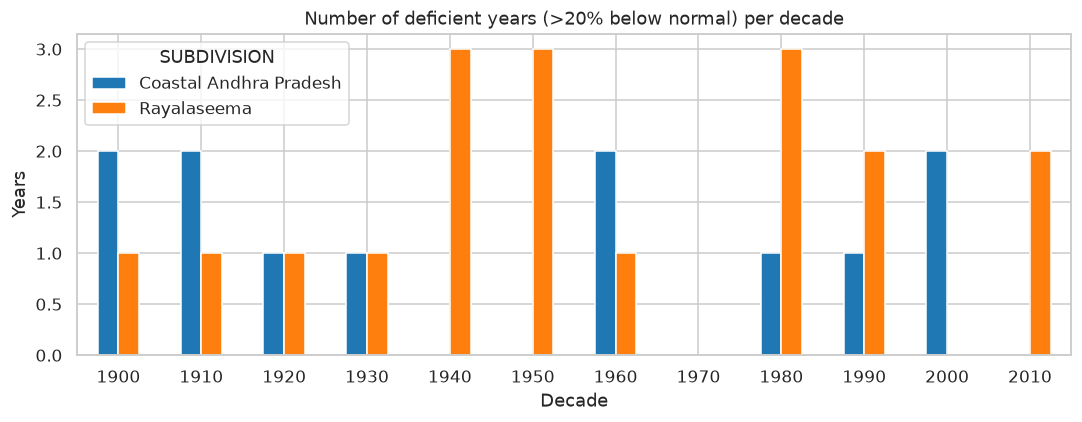

In [9]:
ap_rain["decade"] = (ap_rain["YEAR"] // 10) * 10
deficient = (ap_rain[ap_rain["category"] == "Deficient"]
             .groupby(["decade", "SUBDIVISION"]).size().unstack(fill_value=0)
             .reindex(range(1900, 2020, 10), fill_value=0))

ax = deficient.plot(kind="bar", figsize=(10, 4), color=["#1f77b4", "#ff7f0e"])
ax.set_title("Number of deficient years (>20% below normal) per decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Years")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "drought_years.png")
plt.show()

In [10]:
# driest and wettest years
for name, g in ap_rain.groupby("SUBDIVISION"):
    print(name)
    print("  driest :", g.nsmallest(3, "ANNUAL")[["YEAR", "ANNUAL"]].values.tolist())
    print("  wettest:", g.nlargest(3, "ANNUAL")[["YEAR", "ANNUAL"]].values.tolist())

Coastal Andhra Pradesh
  driest : [[2002.0, 703.2], [1920.0, 723.5], [1935.0, 751.1]]
  wettest: [[2010.0, 1712.4], [1990.0, 1611.1], [1958.0, 1605.3]]
Rayalaseema
  driest : [[1904.0, 433.4], [1950.0, 510.9], [1923.0, 515.8]]
  wettest: [[1996.0, 1277.7], [1903.0, 1138.2], [2005.0, 1066.4]]


Rayalaseema had **18 deficient years** out of 117 (about 1 in 6.5) while Coastal AP had 12. Rayalaseema also has lower rain to begin with, so a bad year hits it harder. 2002 was the driest year on record for Coastal AP (703 mm).